In [1]:

from google.colab import files
uploaded = files.upload()


Saving inteligence.png to inteligence.png


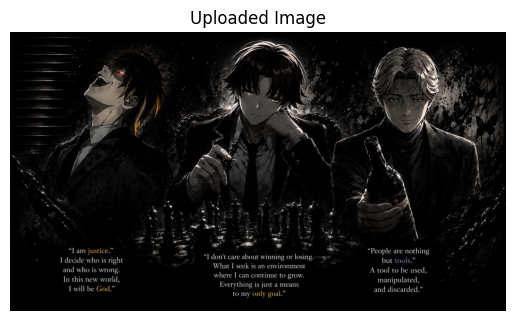

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Uploaded Image")
plt.axis("off")
plt.show()


In [3]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input, decode_predictions
    )

model = MobileNetV2(weights="imagenet")
print("MobileNetV2 model loaded successfully")


14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 model loaded successfully


In [4]:

img = cv2.resize(image_rgb, (224, 224))
img = np.expand_dims(img, axis=0)

img = preprocess_input(img)

predictions = model.predict(img)
results = decode_predictions(predictions, top=5)[0]

for label in results:
    print(label[1], ":", round(label[2] * 100, 2), "%")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
book_jacket : 20.67 %
fountain : 13.34 %
microphone : 4.76 %
brass : 2.34 %
mask : 2.31 %


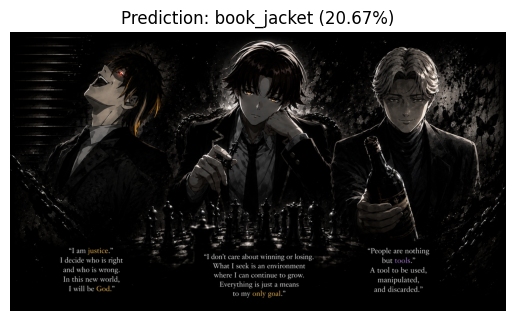

In [5]:

best = results[0]

plt.imshow(image_rgb)
plt.title(f"Prediction: {best[1]} ({best[2]*100:.2f}%)")
plt.axis("off")
plt.show()
